# Redes neuronales · Spaceship Titanic

## 1. Configuración

In [1]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"  # silencia avisos de CUDA al no haber GPU

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import accuracy_score, f1_score

SEMILLA = 42
tf.keras.utils.set_random_seed(SEMILLA)
tf.config.experimental.enable_op_determinism()  # resultados idénticos en cada ejecución

RUTA_DATOS = "data"
RUTA_MODELOS = "modelos"
os.makedirs(RUTA_MODELOS, exist_ok=True)
sns.set_theme(style="whitegrid")

In [2]:
def plot_learning_curve(history, titulo=""):
    """Curvas de accuracy y pérdida (entrenamiento vs validación), como en la clase."""
    fig, ejes = plt.subplots(1, 2, figsize=(11, 3.5))
    ejes[0].plot(history.history["accuracy"], label="Entrenamiento")
    ejes[0].plot(history.history["val_accuracy"], label="Validación")
    ejes[0].set_title(f"Accuracy · {titulo}")
    ejes[1].plot(history.history["loss"], label="Entrenamiento")
    ejes[1].plot(history.history["val_loss"], label="Validación")
    ejes[1].set_title(f"Pérdida · {titulo}")
    for eje in ejes:
        eje.set_xlabel("Época")
        eje.legend()
    plt.tight_layout()
    plt.show()

## 2. Carga y exploración

In [3]:
df = pd.read_csv(f"{RUTA_DATOS}/train.csv")
df_test = pd.read_csv(f"{RUTA_DATOS}/test.csv")
print("train.csv:", df.shape, "· test.csv:", df_test.shape)
df.head(5)

train.csv: (8693, 14) · test.csv: (4277, 13)


,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported
0,0001_01,Europa,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,Maham Ofracculy,False
1,0002_01,Earth,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,Juanna Vines,True
2,0003_01,Europa,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,Altark Susent,False
3,0003_02,Europa,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,Solam Susent,False
4,0004_01,Earth,False,F/1/S,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,Willy Santantines,True


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8693 entries, 0 to 8692
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   PassengerId   8693 non-null   str    
 1   HomePlanet    8492 non-null   str    
 2   CryoSleep     8476 non-null   object 
 3   Cabin         8494 non-null   str    
 4   Destination   8511 non-null   str    
 5   Age           8514 non-null   float64
 6   VIP           8490 non-null   object 
 7   RoomService   8512 non-null   float64
 8   FoodCourt     8510 non-null   float64
 9   ShoppingMall  8485 non-null   float64
 10  Spa           8510 non-null   float64
 11  VRDeck        8505 non-null   float64
 12  Name          8493 non-null   str    
 13  Transported   8693 non-null   bool   
dtypes: bool(1), float64(6), object(2), str(5)
memory usage: 1.2+ MB


In [5]:
df.describe()

,Age,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck
count,8514.000000,8512.000000,8510.000000,8485.000000,8510.000000,8505.000000
mean,28.827930,224.687617,458.077203,173.729169,311.138778,304.854791
std,14.489021,666.717663,1611.489240,604.696458,1136.705535,1145.717189
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,19.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,27.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,38.000000,47.000000,76.000000,27.000000,59.000000,46.000000
max,79.000000,14327.000000,29813.000000,23492.000000,22408.000000,24133.000000


In [6]:
# Porcentaje de nulos por columna (misma expresión que en la clase)
df.isna().sum()[df.isna().sum() > 0] / df.shape[0] * 100

HomePlanet      2.312205
CryoSleep       2.496261
Cabin           2.289198
Destination     2.093639
Age             2.059128
VIP             2.335212
RoomService     2.082135
FoodCourt       2.105142
ShoppingMall    2.392730
Spa             2.105142
VRDeck          2.162660
Name            2.300702
dtype: float64

Todas las columnas, salvo el id y el objetivo, tienen alrededor de **2 % de nulos**. Son pocos, pero hay que imputarlos con cuidado.

In [7]:
df["Transported"].value_counts() / df.shape[0] * 100

Transported
True     50.362361
False    49.637639
Name: count, dtype: float64

Las clases están **balanceadas** (≈ 50/50), así que la *accuracy* es una métrica adecuada; además es la métrica oficial de la competencia en Kaggle.

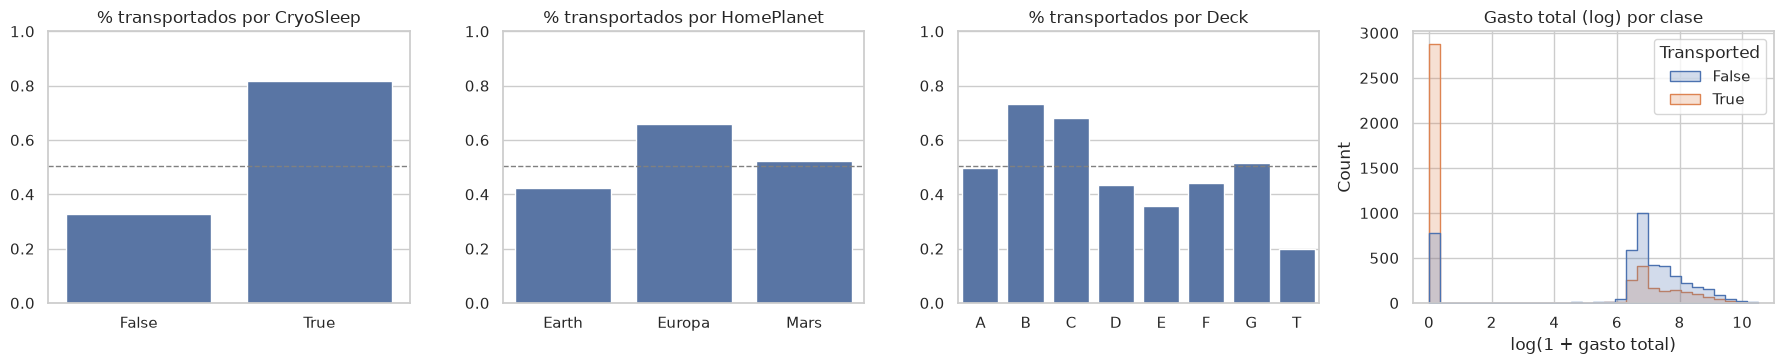

In [8]:
gastos = ["RoomService", "FoodCourt", "ShoppingMall", "Spa", "VRDeck"]
explora = df.assign(
    Deck=df["Cabin"].str.split("/").str[0],
    GastoTotal=df[gastos].sum(axis=1),
)

fig, ejes = plt.subplots(1, 4, figsize=(18, 3.8))
for eje, columna in zip(ejes[:3], ["CryoSleep", "HomePlanet", "Deck"]):
    tasa = explora.groupby(columna)["Transported"].mean().sort_index()
    sns.barplot(x=tasa.index.astype(str), y=tasa.values, ax=eje, color="#4C72B0")
    eje.axhline(df["Transported"].mean(), color="gray", linestyle="--", linewidth=1)
    eje.set_title(f"% transportados por {columna}")
    eje.set_xlabel("")
    eje.set_ylim(0, 1)
sns.histplot(data=explora, x=np.log1p(explora["GastoTotal"]), hue="Transported",
             bins=30, ax=ejes[3], element="step")
ejes[3].set_title("Gasto total (log) por clase")
ejes[3].set_xlabel("log(1 + gasto total)")
plt.tight_layout()
plt.show()

**Lo que se ve:**
- **`CryoSleep` es la señal más fuerte**: la mayoría de quienes iban en criosueño fueron transportados.
- El planeta de origen y la cubierta (`Deck`) también cambian la tasa.
- Quienes **no gastaron nada** fueron transportados mucho más. Tiene sentido: los pasajeros en criosueño están confinados y no pueden gastar.

## 3. Ingeniería de variables

Se aplican las mismas transformaciones a `train.csv` y a `test.csv` con una sola función:

| Columna original | Variables nuevas |
| --- | --- |
| `PassengerId` (`gggg_pp`) | `TamanoGrupo` (cuántas personas viajan en el grupo) y `ViajaSolo` |
| `Cabin` (`deck/num/side`) | `Deck`, `CabNum` y `Side` |
| Los 5 gastos | `GastoTotal` y `SinGasto` |

Además, una **regla del dominio**: quien va en criosueño no puede gastar.
- Si `CryoSleep` es verdadero, sus gastos nulos valen 0.
- Si gastó dinero, su `CryoSleep` nulo pasa a falso.

El tamaño de grupo se cuenta sobre `train.csv` y `test.csv` juntos: es información que se conoce al abordar, no depende del objetivo.

In [9]:
TAMANO_GRUPO = pd.concat([df["PassengerId"], df_test["PassengerId"]]).str[:4].value_counts()


def preparar(datos):
    """Crea las variables nuevas y elimina las columnas que ya no se usan."""
    X = datos.copy()

    # PassengerId -> tamaño del grupo
    grupo = X["PassengerId"].str[:4]
    X["TamanoGrupo"] = grupo.map(TAMANO_GRUPO).astype(float)
    X["ViajaSolo"] = (X["TamanoGrupo"] == 1).astype(float)

    # Cabin -> Deck / CabNum / Side
    cabina = X["Cabin"].str.split("/", expand=True)
    X["Deck"], X["CabNum"], X["Side"] = cabina[0], cabina[1].astype(float), cabina[2]

    # Booleanos a 0/1 (los nulos se quedan como NaN para imputarlos después)
    for columna in ["CryoSleep", "VIP"]:
        X[columna] = X[columna].map({True: 1.0, False: 0.0, "True": 1.0, "False": 0.0})

    # Regla del dominio: en criosueño no se gasta
    en_crio = X["CryoSleep"] == 1
    X.loc[en_crio, gastos] = X.loc[en_crio, gastos].fillna(0)
    gasto_conocido = X[gastos].sum(axis=1)
    X.loc[X["CryoSleep"].isna() & (gasto_conocido > 0), "CryoSleep"] = 0.0

    return X.drop(columns=["PassengerId", "Name", "Cabin"])


X_todo = preparar(df.drop(columns="Transported"))
y_todo = df["Transported"].astype(int)
X_kaggle = preparar(df_test)
ids_kaggle = df_test["PassengerId"]
X_todo.head()

,HomePlanet,CryoSleep,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,TamanoGrupo,ViajaSolo,Deck,CabNum,Side
0,Europa,0.0,TRAPPIST-1e,39.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,B,0.0,P
1,Earth,0.0,TRAPPIST-1e,24.0,0.0,109.0,9.0,25.0,549.0,44.0,1.0,1.0,F,0.0,S
2,Europa,0.0,TRAPPIST-1e,58.0,1.0,43.0,3576.0,0.0,6715.0,49.0,2.0,0.0,A,0.0,S
3,Europa,0.0,TRAPPIST-1e,33.0,0.0,0.0,1283.0,371.0,3329.0,193.0,2.0,0.0,A,0.0,S
4,Earth,0.0,TRAPPIST-1e,16.0,0.0,303.0,70.0,151.0,565.0,2.0,1.0,1.0,F,1.0,S


## 4. División y preprocesamiento

`train.csv` se divide en **70 % entrenamiento, 15 % validación y 15 % prueba**, estratificado como en la clase:
- Con **validación** se eligen la época y el modelo.
- **Prueba** solo se usa al final, para una medición honesta.

Imputación, codificación y escala se **ajustan solo con entrenamiento** y después se aplican igual a validación, prueba y `test.csv`. Así no se filtra información de los datos que se usan para evaluar.

| Tipo | Columnas | Imputación | Transformación |
| --- | --- | --- | --- |
| Categóricas | `HomePlanet`, `Destination`, `Deck`, `Side` | Moda | `OneHotEncoder` |
| Binarias | `CryoSleep`, `VIP` | Moda | Ninguna (ya son 0/1) |
| Gastos | 5 gastos | Mediana | `log1p` y `StandardScaler`; después se recalculan `GastoTotal` y `SinGasto` |
| Numéricas | `Age`, `CabNum`, `TamanoGrupo`, `ViajaSolo` | Mediana | `StandardScaler` |

In [10]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X_todo, y_todo, test_size=0.30, random_state=SEMILLA, stratify=y_todo
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=SEMILLA, stratify=y_temp
)
for nombre, y in [("Entrenamiento", y_train), ("Validación", y_val), ("Prueba", y_test)]:
    print(f"{nombre:<14} {len(y):>5} filas · {y.mean():.1%} transportados")

Entrenamiento   6085 filas · 50.4% transportados
Validación      1304 filas · 50.3% transportados
Prueba          1304 filas · 50.4% transportados


In [11]:
CATEGORICAS = ["HomePlanet", "Destination", "Deck", "Side"]
BINARIAS = ["CryoSleep", "VIP"]
NUMERICAS = ["Age", "CabNum", "TamanoGrupo", "ViajaSolo"] + gastos + ["GastoTotal"]


class Preprocesador:
    """Imputa, codifica y escala. Todo se ajusta con `ajustar` y se aplica con `transformar`."""

    def ajustar(self, X):
        self.modas = {c: X[c].mode().iloc[0] for c in CATEGORICAS + BINARIAS}
        self.medianas = {c: X[c].median() for c in ["Age", "CabNum", "TamanoGrupo", "ViajaSolo"] + gastos}
        X = self._imputar(X)
        self.encoder = OneHotEncoder(sparse_output=False, handle_unknown="ignore").fit(X[CATEGORICAS])
        self.scaler = StandardScaler().fit(X[NUMERICAS])
        return self

    def _imputar(self, X):
        X = X.fillna(self.modas).fillna(self.medianas)
        X["GastoTotal"] = X[gastos].sum(axis=1)
        X["SinGasto"] = (X["GastoTotal"] == 0).astype(float)
        X[gastos + ["GastoTotal"]] = np.log1p(X[gastos + ["GastoTotal"]])
        return X

    def transformar(self, X):
        X = self._imputar(X)
        partes = [
            pd.DataFrame(self.scaler.transform(X[NUMERICAS]), columns=NUMERICAS, index=X.index),
            X[BINARIAS + ["SinGasto"]].astype(float),
            pd.DataFrame(self.encoder.transform(X[CATEGORICAS]),
                         columns=self.encoder.get_feature_names_out(CATEGORICAS), index=X.index),
        ]
        return pd.concat(partes, axis=1).astype("float32")


prep = Preprocesador().ajustar(X_train)
Xp_train, Xp_val, Xp_test = (prep.transformar(X) for X in (X_train, X_val, X_test))
print("Variables de entrada:", Xp_train.shape[1])
print("Nulos después de preprocesar:", int(Xp_train.isna().sum().sum() + Xp_val.isna().sum().sum()))
Xp_train.head()

Variables de entrada: 29
Nulos después de preprocesar: 0


,Age,CabNum,TamanoGrupo,ViajaSolo,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,GastoTotal,...,Deck_A,Deck_B,Deck_C,Deck_D,Deck_E,Deck_F,Deck_G,Deck_T,Side_P,Side_S
3395,-0.043018,-0.002846,-0.649965,0.897573,-0.641615,-0.648109,-0.617067,-0.655084,-0.640846,-1.145409,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0
7906,0.236272,-0.543797,-0.016145,-1.114115,-0.641615,1.970950,-0.617067,2.678672,1.831142,1.411083,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
1760,0.166449,-1.031443,-0.649965,0.897573,-0.641615,1.942739,-0.617067,1.217307,0.811664,0.938297,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
1704,-0.252485,-0.606974,-0.016145,-1.114115,-0.641615,-0.648109,-0.617067,-0.655084,-0.640846,-1.145409,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0
8025,-0.182663,-0.642511,-0.649965,0.897573,0.071008,1.601110,-0.617067,1.942759,1.926799,1.032208,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0


## 5. Tres redes neuronales

| Modelo | Arquitectura | Qué se prueba |
| --- | --- | --- |
| **M1** · logística | `Dense(1, sigmoid)` | La red de la clase: una sola neurona, frontera lineal |
| **M2** · MLP | `64 ReLU → 32 ReLU → 1 sigmoid` | ¿Ayudan las capas ocultas a capturar combinaciones? |
| **M3** · MLP + Dropout | `64 ReLU → Dropout 0.3 → 32 ReLU → Dropout 0.3 → 1 sigmoid` | ¿Reduce el sobreajuste? |

Entrenamiento común:
- Optimizador `adam` y pérdida `BinaryCrossentropy`; métricas `accuracy` y `F1Score` (la de la clase).
- Hasta 200 épocas en lotes de 32.
- `EarlyStopping` sobre `val_loss` con paciencia 15, y `ModelCheckpoint` que guarda el mejor modelo en `modelos/`, como en la Clase 07.

In [12]:
def construir_red(ocultas, dropout=0.0, nombre="red"):
    tf.keras.utils.set_random_seed(SEMILLA)  # misma inicialización en cada ejecución
    capas = [tf.keras.layers.Input(shape=(Xp_train.shape[1],))]
    for unidades in ocultas:
        capas.append(tf.keras.layers.Dense(units=unidades, activation="relu"))
        if dropout > 0:
            capas.append(tf.keras.layers.Dropout(dropout))
    capas.append(tf.keras.layers.Dense(units=1, activation="sigmoid"))
    red = tf.keras.Sequential(capas, name=nombre)
    red.compile(
        optimizer="adam",
        loss=tf.keras.losses.BinaryCrossentropy(from_logits=False),
        metrics=["accuracy", tf.keras.metrics.F1Score(threshold=0.5)],
    )
    return red


def a_columna(y):
    """F1Score de Keras espera la etiqueta como columna float32."""
    return np.asarray(y, dtype="float32").reshape(-1, 1)


def entrenar(red, nombre):
    callbacks = [
        tf.keras.callbacks.EarlyStopping(monitor="val_loss", mode="min", patience=15,
                                         restore_best_weights=True),
        tf.keras.callbacks.ModelCheckpoint(filepath=f"{RUTA_MODELOS}/{nombre}.keras",
                                           monitor="val_loss", mode="min", save_best_only=True),
    ]
    return red.fit(Xp_train, a_columna(y_train), epochs=200, batch_size=32,
                   validation_data=(Xp_val, a_columna(y_val)), callbacks=callbacks, verbose=0)


CONFIGS = {
    "M1 · logística": dict(ocultas=[]),
    "M2 · MLP": dict(ocultas=[64, 32]),
    "M3 · MLP + Dropout": dict(ocultas=[64, 32], dropout=0.3),
}
redes, historias = {}, {}

### M1 · logística (una neurona sigmoide)

Model: "M1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 1)              │            30 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 30 (120.00 B)

 Trainable params: 30 (120.00 B)

 Non-trainable params: 0 (0.00 B)

Se detuvo en la época 37


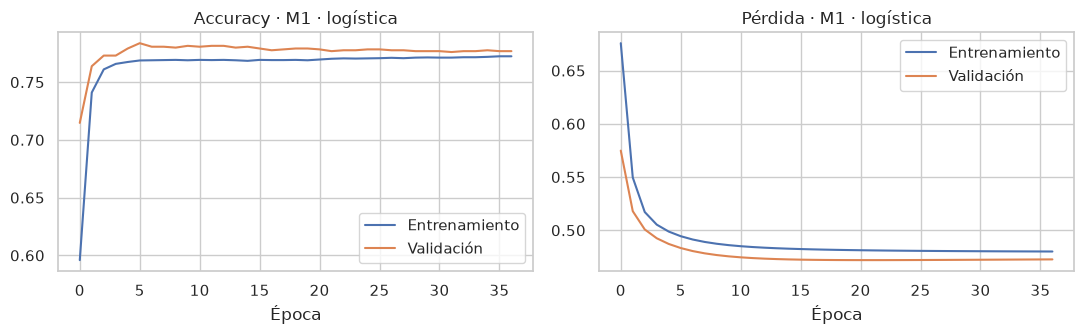

In [13]:
nombre = "M1 · logística"
redes[nombre] = construir_red(**CONFIGS[nombre], nombre="M1")
redes[nombre].summary()
historias[nombre] = entrenar(redes[nombre], "M1")
print(f"Se detuvo en la época {len(historias[nombre].history['loss'])}")
plot_learning_curve(historias[nombre], nombre)

### M2 · MLP 64 → 32

Model: "M2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_1 (Dense)                 │ (None, 64)             │         1,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,033 (15.75 KB)

 Trainable params: 4,033 (15.75 KB)

 Non-trainable params: 0 (0.00 B)

Se detuvo en la época 28


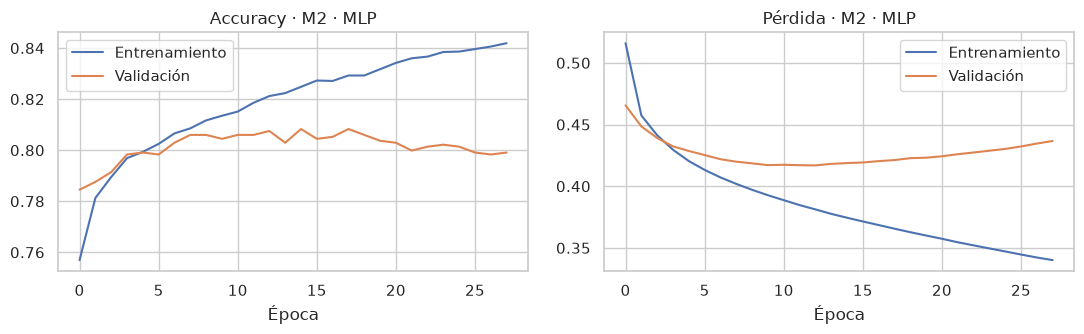

In [14]:
nombre = "M2 · MLP"
redes[nombre] = construir_red(**CONFIGS[nombre], nombre="M2")
redes[nombre].summary()
historias[nombre] = entrenar(redes[nombre], "M2")
print(f"Se detuvo en la época {len(historias[nombre].history['loss'])}")
plot_learning_curve(historias[nombre], nombre)

### M3 · MLP 64 → 32 con Dropout 0.3

Model: "M3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                 │ (None, 64)             │         1,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,033 (15.75 KB)

 Trainable params: 4,033 (15.75 KB)

 Non-trainable params: 0 (0.00 B)

Se detuvo en la época 43


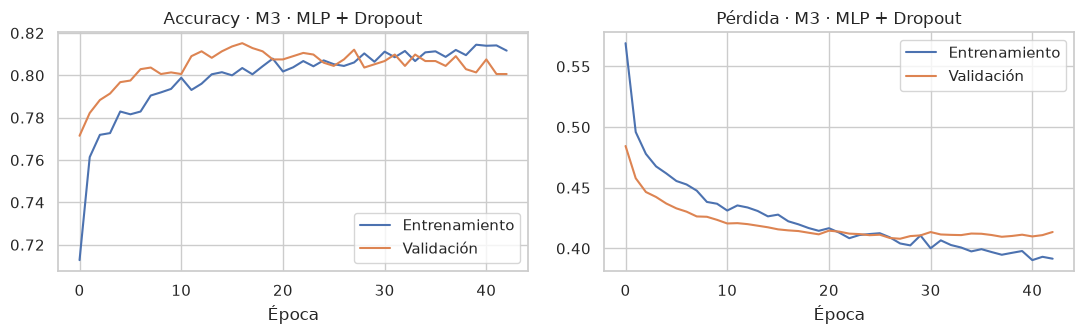

In [15]:
nombre = "M3 · MLP + Dropout"
redes[nombre] = construir_red(**CONFIGS[nombre], nombre="M3")
redes[nombre].summary()
historias[nombre] = entrenar(redes[nombre], "M3")
print(f"Se detuvo en la época {len(historias[nombre].history['loss'])}")
plot_learning_curve(historias[nombre], nombre)

### Comparación en validación

In [16]:
def medir(red, X, y):
    prob = red.predict(X, verbose=0).ravel()
    pred = (prob > 0.5).astype(int)
    return accuracy_score(y, pred), f1_score(y, pred)


filas = []
for nombre, red in redes.items():
    h = historias[nombre].history
    acc_tr, _ = medir(red, Xp_train, y_train)
    acc_val, f1_val = medir(red, Xp_val, y_val)
    filas.append({
        "Modelo": nombre,
        "Parámetros": red.count_params(),
        "Mejor época": int(np.argmin(h["val_loss"])) + 1,
        "Accuracy entrenamiento": acc_tr,
        "Accuracy validación": acc_val,
        "F1 validación": f1_val,
    })
comparacion = pd.DataFrame(filas).set_index("Modelo")
comparacion.style.format({"Accuracy entrenamiento": "{:.4f}", "Accuracy validación": "{:.4f}",
                          "F1 validación": "{:.4f}", "Parámetros": "{:,}"})

,Parámetros,Mejor época,Accuracy entrenamiento,Accuracy validación,F1 validación
Modelo,,,,,
M1 · logística,30,22,0.7719,0.7768,0.7814
M2 · MLP,"4,033",13,0.8232,0.8075,0.8010
M3 · MLP + Dropout,"4,033",28,0.8240,0.8121,0.8063


In [17]:
mejor_nombre = comparacion["Accuracy validación"].idxmax()
mejor_red = redes[mejor_nombre]
print(f"Mejor modelo en validación: {mejor_nombre}")

Mejor modelo en validación: M3 · MLP + Dropout


## 6. Evaluación del mejor modelo en prueba

M3 · MLP + Dropout en prueba (1304 pasajeros)
  Accuracy: 0.7952
  F1:       0.7842


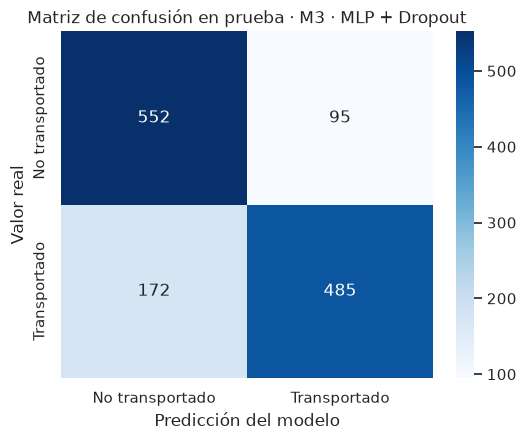

In [18]:
acc_test, f1_test = medir(mejor_red, Xp_test, y_test)
print(f"{mejor_nombre} en prueba ({len(y_test)} pasajeros)")
print(f"  Accuracy: {acc_test:.4f}")
print(f"  F1:       {f1_test:.4f}")

y_predict = mejor_red.predict(Xp_test, verbose=0).ravel() > 0.5
matriz_confusion = tf.math.confusion_matrix(labels=y_test, predictions=y_predict)
plt.figure(figsize=(6, 4.5))
sns.heatmap(matriz_confusion, annot=True, fmt="d", cmap="Blues",
            xticklabels=["No transportado", "Transportado"],
            yticklabels=["No transportado", "Transportado"])
plt.xlabel("Predicción del modelo")
plt.ylabel("Valor real")
plt.title(f"Matriz de confusión en prueba · {mejor_nombre}")
plt.show()

### ¿Qué variables usa más el modelo?

**Importancia por permutación:** se revuelve una columna original a la vez en el conjunto de prueba y se mide cuánto baja la accuracy. Si baja mucho, el modelo depende de esa variable. Se repite 5 veces por columna y se promedia.

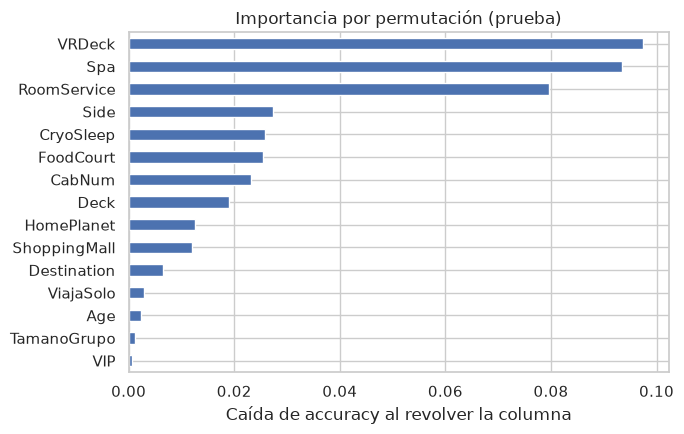

In [19]:
rng = np.random.default_rng(SEMILLA)
base = medir(mejor_red, Xp_test, y_test)[0]
importancias = {}
for columna in X_test.columns:
    caidas = []
    for _ in range(5):
        X_rev = X_test.copy()
        X_rev[columna] = rng.permutation(X_rev[columna].values)
        caidas.append(base - medir(mejor_red, prep.transformar(X_rev), y_test)[0])
    importancias[columna] = np.mean(caidas)

importancias = pd.Series(importancias).sort_values()
plt.figure(figsize=(7, 4.5))
importancias.plot.barh(color="#4C72B0")
plt.xlabel("Caída de accuracy al revolver la columna")
plt.title("Importancia por permutación (prueba)")
plt.tight_layout()
plt.show()

## 7. Predicción para `test.csv` y archivo de entrega

Ya elegidos el modelo y su número de épocas, se **reentrena con entrenamiento + validación**, con más datos y la misma arquitectura y épocas. El preprocesador también se reajusta con esos datos.

La partición de prueba sigue fuera, así que sirve para confirmar que el modelo reentrenado no empeoró. Después se predice `test.csv` y se escribe `submission.csv` con el formato de `sample_submission.csv`.

In [20]:
X_final = pd.concat([X_train, X_val])
y_final = pd.concat([y_train, y_val])
epocas = int(comparacion.loc[mejor_nombre, "Mejor época"])

prep_final = Preprocesador().ajustar(X_final)
red_final = construir_red(**CONFIGS[mejor_nombre], nombre="final")
red_final.fit(prep_final.transformar(X_final), a_columna(y_final),
              epochs=epocas, batch_size=32, verbose=0)
red_final.save(f"{RUTA_MODELOS}/final.keras")

acc_final, f1_final = medir(red_final, prep_final.transformar(X_test), y_test)
print(f"Modelo final ({mejor_nombre}, {epocas} épocas) en prueba: "
      f"accuracy {acc_final:.4f} · F1 {f1_final:.4f}")

Modelo final (M3 · MLP + Dropout, 28 épocas) en prueba: accuracy 0.7845 · F1 0.7775


In [21]:
prob_kaggle = red_final.predict(prep_final.transformar(X_kaggle), verbose=0).ravel()
submission = pd.DataFrame({"PassengerId": ids_kaggle, "Transported": prob_kaggle > 0.5})
submission.to_csv("submission.csv", index=False)

# Validación contra el formato de ejemplo
ejemplo = pd.read_csv(f"{RUTA_DATOS}/sample_submission.csv")
assert list(submission.columns) == list(ejemplo.columns)
assert len(submission) == len(ejemplo)
assert (submission["PassengerId"].values == ejemplo["PassengerId"].values).all()
assert submission["Transported"].dtype == bool

print(f"submission.csv: {len(submission)} filas · {submission['Transported'].mean():.1%} predichos como transportados")
submission.head()

submission.csv: 4277 filas · 47.7% predichos como transportados


,PassengerId,Transported
0,0013_01,False
1,0018_01,False
2,0019_01,True
3,0021_01,True
4,0023_01,True


## 8. Conclusiones

**Resultados**

| Modelo | Accuracy validación | F1 validación |
| --- | --- | --- |
| M1 · logística | 0.7768 | 0.7814 |
| M2 · MLP 64→32 | 0.8075 | 0.8010 |
| **M3 · MLP + Dropout** | **0.8121** | **0.8063** |

- **Las capas ocultas sí ayudan:**
  - Pasar de una neurona (M1) a un MLP sube la accuracy unos 3 puntos.
  - La frontera lineal no capta combinaciones como "en criosueño **y** cubierta B".
- **Dropout:**
  - M3 empata o supera ligeramente a M2.
  - Su principal aporte es que el entrenamiento es más estable: alcanza su mejor `val_loss` más tarde, en la época 28 frente a la 13, y sobreajusta menos.
  - La diferencia está dentro del ruido de 1,304 pasajeros (±1.1 puntos), así que M2 y M3 son prácticamente equivalentes.
- **En prueba**, M3 obtiene accuracy de **0.7952** y F1 de **0.7842**.
  - Al reentrenarlo con entrenamiento y validación, la accuracy en prueba fue 0.7845.
  - La diferencia está dentro del mismo margen de ruido: no es una mejora ni un deterioro real. Ese modelo final es el que genera `submission.csv`.
- **Variables clave:**
  - Los **gastos** pesan más que todo lo demás, en especial `VRDeck`, `Spa` y `RoomService`.
  - Después vienen el lado de la cabina, `CryoSleep` y la cubierta.
  - `CryoSleep` parece poco importante en la permutación porque su información ya está en los gastos: quien va en criosueño gasta 0. La regla del dominio de la sección 3 refleja esa relación.
  - `VIP`, `Age` y el tamaño del grupo casi no aportan.
  